<a href="https://colab.research.google.com/github/RodrigoMesel/RNA-e-Deep-Learning---CESAR-School-2026.01-A/blob/main/Atividade2/regressao_linear_california_housing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regressão Linear Múltipla em PyTorch: California Housing

## Objetivos

- Treinar um modelo de regressão linear múltipla (`nn.Linear(8, 1)`) em PyTorch para prever o preço mediano de imóveis na Califórnia a partir de 8 variáveis de entrada.
- Explorar o dataset **California Housing** (`scikit-learn`), entendendo o significado e a distribuição de cada variável.
- Dividir os dados em conjuntos de **treino (70%)**, **validação (15%)** e **teste (15%)** com `random_state` fixo.
- Padronizar entradas e saída com `StandardScaler` ajustado **exclusivamente no treino** (evitando vazamento de dados).
- Treinar com `nn.MSELoss` e `optim.SGD`, acompanhando as curvas de custo de treino e de validação.
- Avaliar o modelo no conjunto de teste usando **RMSE em dólares** e comparar com um baseline que prevê sempre a média do treino.
- Interpretar os 8 pesos aprendidos e concluir sobre a qualidade do modelo e possíveis melhorias.

No notebook anterior (`2.6_regressao_linear_salarios.ipynb`), o modelo tinha apenas 1 variável de entrada (`nn.Linear(1, 1)`). Aqui, com 8 variáveis de entrada, a previsão passa a ser um hiperplano:

$$\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_8 x_8 = \mathbf{w}^\top \mathbf{x} + b$$

implementado pela camada `nn.Linear(8, 1)`, que possui 8 pesos (`model.weight`) e 1 bias (`model.bias`).

## Importação das bibliotecas

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

## 1. Carregamento e análise exploratória dos dados

O dataset **California Housing** reúne informações de **20.640 grupos censitários (quarteirões)** da Califórnia, coletadas no censo dos EUA de 1990. Cada linha representa um quarteirão com 8 variáveis explicativas e 1 variável alvo:

| Variável | Significado |
| :--- | :--- |
| **`MedInc`** | Renda mediana dos moradores do quarteirão (em dezenas de milhares de dólares). |
| **`HouseAge`** | Idade mediana das casas no quarteirão (em anos). |
| **`AveRooms`** | Número médio de cômodos por domicílio. |
| **`AveBedrms`** | Número médio de quartos (dormitórios) por domicílio. |
| **`Population`** | População total do quarteirão. |
| **`AveOccup`** | Número médio de moradores por domicílio (ocupação média). |
| **`Latitude`** | Latitude do quarteirão (quanto maior, mais ao norte). |
| **`Longitude`** | Longitude do quarteirão (valores negativos; quanto maior/menos negativo, mais a leste/interior). |
| **`MedHouseVal` (alvo `y`)** | Valor mediano das casas no quarteirão, em **centenas de milhares de dólares** (ex.: `2.5` = US$ 250.000). Valores acima de US$ 500.000 foram truncados em `5.00001`. |

In [2]:
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target  # 20.640 quarteirões, 8 variáveis; y em centenas de milhares de dólares

df = dados.frame.copy()
print('Shape de X:', X.shape)
print('Shape de y:', y.shape)
print('Valores ausentes no dataset:', df.isna().sum().sum())
df.head()

Shape de X: (20640, 8)
Shape de y: (20640,)
Valores ausentes no dataset: 0


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


### Estatísticas descritivas (`describe()`)

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


Observações iniciais a partir do `describe()`:
- As variáveis possuem **escalas muito diferentes**: `Population` varia de 3 até 35.682 (média ~1.425), enquanto `AveBedrms` tem média ~1,1 e `MedInc` tem média ~3,87.
- Há presença de **outliers fortes** em `AveRooms` (máximo 141,9), `AveBedrms` (máximo 34,1) e `AveOccup` (máximo 1.243,3), provavelmente correspondendo a áreas com hotéis ou propriedades rurais/sazonais.
- O alvo `MedHouseVal` tem média de ~2,07 (US$ 207 mil) e apresenta um **teto (capping)** em `5.00001` (US$ 500 mil).

### Gráficos de dispersão contra o preço

Abaixo plotamos a relação entre o preço das casas (convertido para dólares) e três variáveis: renda mediana (`MedInc`), idade mediana das casas (`HouseAge`) e latitude (`Latitude`).

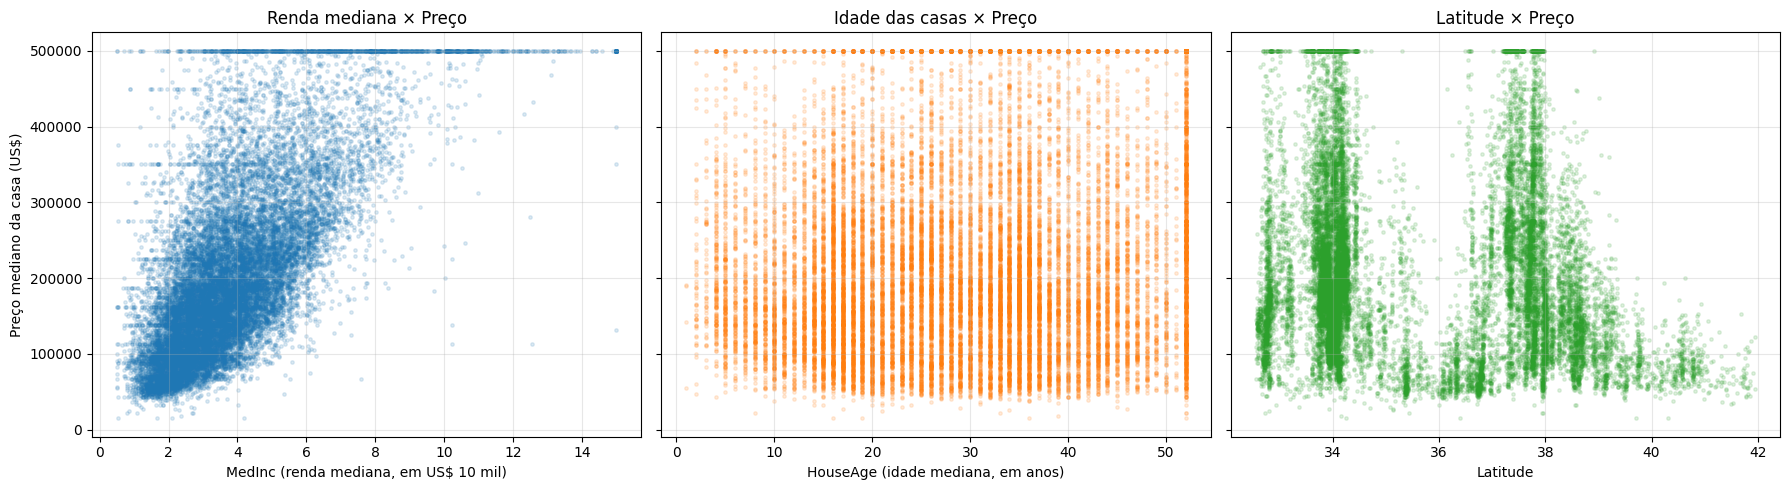

In [4]:
preco_dolares = y * 100_000

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

axes[0].scatter(X['MedInc'], preco_dolares, alpha=0.15, s=6, color='tab:blue')
axes[0].set_xlabel('MedInc (renda mediana, em US$ 10 mil)')
axes[0].set_ylabel('Preço mediano da casa (US$)')
axes[0].set_title('Renda mediana × Preço')
axes[0].grid(True, alpha=0.3)

axes[1].scatter(X['HouseAge'], preco_dolares, alpha=0.15, s=6, color='tab:orange')
axes[1].set_xlabel('HouseAge (idade mediana, em anos)')
axes[1].set_title('Idade das casas × Preço')
axes[1].grid(True, alpha=0.3)

axes[2].scatter(X['Latitude'], preco_dolares, alpha=0.15, s=6, color='tab:green')
axes[2].set_xlabel('Latitude')
axes[2].set_title('Latitude × Preço')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Nos gráficos de dispersão ficam evidentes:
- Uma **correlação positiva clara** entre `MedInc` e o preço: quarteirões com maior renda tendem a ter casas mais caras.
- A linha horizontal no topo (US$ 500.000), confirmando o truncamento dos preços mais altos no dataset.
- Em `HouseAge` e `Latitude`, a relação isolada é bem mais dispersa e não linear (por exemplo, os dois picos em `Latitude` perto de 34° e 38° correspondem às regiões metropolitanas de Los Angeles e São Francisco/Bay Area).

## 2. Divisão em treino, validação e teste (70/15/15)

Diferente do notebook 2.6 (que tinha apenas 30 amostras e só separava treino e validação), aqui temos 20.640 amostras. Isso permite separar três conjuntos independentes com `random_state=42`:

- **Treino (70%)**: usado para ajustar os parâmetros do modelo e calcular a média e o desvio padrão da padronização.
- **Validação (15%)**: usado para monitorar o custo durante o treinamento e escolher hiperparâmetros (como taxa de aprendizado e número de épocas).
- **Teste (15%)**: mantido completamente isolado até o final para estimar o erro real em dados inéditos.

In [5]:
x_raw = X.to_numpy()                     # (20640, 8)
y_raw = y.to_numpy().reshape(-1, 1)      # (20640, 1)

# Primeiro separa 70% treino e 30% temporário
x_train_raw, x_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    x_raw, y_raw, test_size=0.30, random_state=42
)

# Divide os 30% restantes ao meio: 15% validação e 15% teste
x_val_raw, x_test_raw, y_val_raw, y_test_raw = train_test_split(
    x_temp_raw, y_temp_raw, test_size=0.50, random_state=42
)

print(f'Treino:    X={x_train_raw.shape}, y={y_train_raw.shape} ({len(x_train_raw)/len(x_raw):.0%})')
print(f'Validação: X={x_val_raw.shape},  y={y_val_raw.shape}  ({len(x_val_raw)/len(x_raw):.0%})')
print(f'Teste:     X={x_test_raw.shape},  y={y_test_raw.shape}  ({len(x_test_raw)/len(x_raw):.0%})')

Treino:    X=(14448, 8), y=(14448, 1) (70%)
Validação: X=(3096, 8),  y=(3096, 1)  (15%)
Teste:     X=(3096, 8),  y=(3096, 1)  (15%)


## 3. Padronização das entradas e da saída

Padronizamos cada variável de entrada e a variável de saída via z-score:

$$z = \frac{x - \mu}{\sigma}$$

Os objetos `StandardScaler` são ajustados (`fit`) **somente nos dados de treino** e depois aplicados (`transform`) ao treino, à validação e ao teste. Ajustar o scaler no dataset inteiro causaria **vazamento de dados (data leakage)**, pois estatísticas da validação e do teste influenciariam o treinamento.

In [6]:
x_scaler = StandardScaler().fit(x_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

x_train = torch.from_numpy(x_scaler.transform(x_train_raw)).float()
y_train = torch.from_numpy(y_scaler.transform(y_train_raw)).float()

x_val = torch.from_numpy(x_scaler.transform(x_val_raw)).float()
y_val = torch.from_numpy(y_scaler.transform(y_val_raw)).float()

x_test = torch.from_numpy(x_scaler.transform(x_test_raw)).float()
y_test = torch.from_numpy(y_scaler.transform(y_test_raw)).float()

print('x_train:', x_train.shape, '| média máx abs:', x_train.mean(dim=0).abs().max().item(), '| std médio:', x_train.std(dim=0).mean().item())
print('x_val:  ', x_val.shape,   '| y_val: ', y_val.shape)
print('x_test: ', x_test.shape,  '| y_test:', y_test.shape)

x_train: torch.Size([14448, 8]) | média máx abs: 6.336706270815284e-09 | std médio: 1.0000344514846802
x_val:   torch.Size([3096, 8]) | y_val:  torch.Size([3096, 1])
x_test:  torch.Size([3096, 8]) | y_test: torch.Size([3096, 1])


## 4. Modelo, função de custo e otimizador

Usamos `nn.Linear(8, 1)` (8 entradas, 1 saída, com `bias=True` por padrão), `nn.MSELoss()` como função de custo e `optim.SGD` como otimizador.

Como existem variáveis fortemente correlacionadas entre si (por exemplo, `Latitude` e `Longitude`, e `AveRooms` e `AveBedrms`), escolhemos uma taxa de aprendizado moderada (`lr = 0.3`) e `200` épocas para garantir convergência estável de todos os pesos.

In [8]:
torch.manual_seed(1234)
model = nn.Linear(8, 1)

lr = 0.3
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)

print('Pesos iniciais:', model.weight.detach().numpy().round(4))
print('Bias inicial:  ', round(model.bias.item(), 4))

Pesos iniciais: [[-0.3331 -0.0694 -0.1698 -0.0943 -0.3123  0.1419 -0.3169 -0.0225]]
Bias inicial:   0.1229


## 5. Treinamento e curvas de custo

Reaproveitamos as funções `train_epoch` e `validate_epoch` do notebook 2.6, mantendo o padrão do PyTorch com `model.train()`, `model.eval()` e `torch.no_grad()`.

In [9]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()
    optimizer.zero_grad()

    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)

    loss.backward()
    optimizer.step()

    return loss.item()


def validate_epoch(model, criterion, x_val, y_val):
    model.eval()
    with torch.no_grad():
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

In [10]:
n_epochs = 200
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    train_loss = train_epoch(model, optimizer, criterion, x_train, y_train)
    train_losses.append(train_loss)

    val_loss = validate_epoch(model, criterion, x_val, y_val)
    val_losses.append(val_loss)

    if (epoch + 1) % 100 == 0 or epoch == 0:
        print(f'Epoch[{epoch + 1:3d}/{n_epochs}], Train Loss: {train_loss:.6f}, Val Loss: {val_loss:.6f}')

Epoch[  1/200], Train Loss: 1.784641, Val Loss: 0.656895
Epoch[100/200], Train Loss: 0.390662, Val Loss: 0.403759
Epoch[200/200], Train Loss: 0.390654, Val Loss: 0.403732


### Curvas de custo de treino e de validação

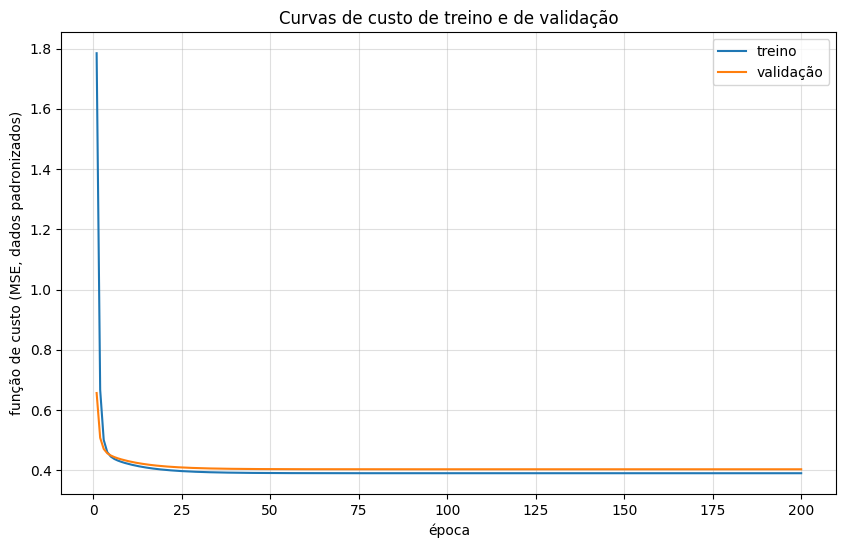

MSE final (padronizado) -> treino: 0.390654 | validação: 0.403732


In [11]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, n_epochs + 1), train_losses, label='treino')
plt.plot(range(1, n_epochs + 1), val_losses, label='validação')
plt.xlabel('época')
plt.ylabel('função de custo (MSE, dados padronizados)')
plt.title('Curvas de custo de treino e de validação')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

print(f'MSE final (padronizado) -> treino: {train_losses[-1]:.6f} | validação: {val_losses[-1]:.6f}')

## 6. Avaliação no teste: RMSE em dólares × baseline da média

Para interpretar o erro em termos práticos, levamos as previsões do conjunto de **teste** de volta à escala original com `y_scaler.inverse_transform` e multiplicamos por `100_000` para obter valores em **dólares**.

Em seguida, calculamos o **RMSE**:

$$\text{RMSE} = \sqrt{\frac{1}{M_{\text{teste}}} \sum_{i=1}^{M_{\text{teste}}} \left(\hat{y}^{(i)} - y^{(i)}\right)^2}$$

e comparamos com um **modelo baseline** que ignora todas as 8 variáveis e prevê sempre o **preço médio do conjunto de treino**.

In [12]:
model.eval()
with torch.no_grad():
    y_test_pred_pad = model(x_test).numpy()

# Volta para a escala original (centenas de milhares de dólares) e converte para dólares
y_test_pred_dolares = y_scaler.inverse_transform(y_test_pred_pad) * 100_000
y_test_real_dolares = y_test_raw * 100_000

# RMSE do modelo no teste (em dólares)
rmse_teste = np.sqrt(np.mean((y_test_pred_dolares - y_test_real_dolares) ** 2))

# Baseline: sempre prevê a média do preço no treino
preco_medio_treino_dolares = y_train_raw.mean() * 100_000
y_baseline_dolares = np.full_like(y_test_real_dolares, preco_medio_treino_dolares)
rmse_baseline = np.sqrt(np.mean((y_baseline_dolares - y_test_real_dolares) ** 2))

reducao_pct = (1 - rmse_teste / rmse_baseline) * 100

print(f'Preço médio no treino:         US$ {preco_medio_treino_dolares:,.2f}')
print(f'RMSE do baseline (média):      US$ {rmse_baseline:,.2f}')
print(f'RMSE da regressão linear:      US$ {rmse_teste:,.2f}')
print(f'Redução do erro sobre baseline: {reducao_pct:.1f}%')

Preço médio no treino:         US$ 206,923.96
RMSE do baseline (média):      US$ 114,992.22
RMSE da regressão linear:      US$ 72,130.27
Redução do erro sobre baseline: 37.3%


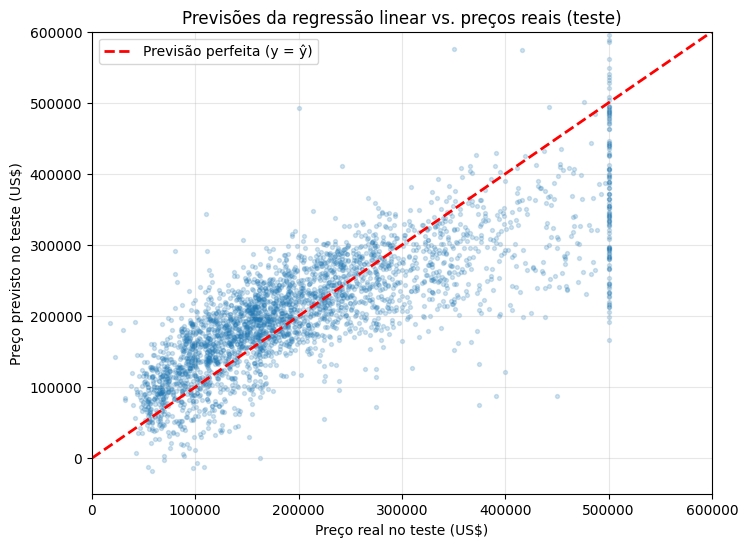

In [13]:
# Gráfico de valores reais vs. previstos no conjunto de teste
plt.figure(figsize=(8, 6))
plt.scatter(y_test_real_dolares, y_test_pred_dolares, alpha=0.2, s=8)
lim_min = 0
lim_max = 600_000
plt.plot([lim_min, lim_max], [lim_min, lim_max], 'r--', lw=2, label='Previsão perfeita (y = ŷ)')
plt.xlim(lim_min, lim_max)
plt.ylim(-50_000, lim_max)
plt.xlabel('Preço real no teste (US$)')
plt.ylabel('Preço previsto no teste (US$)')
plt.title('Previsões da regressão linear vs. preços reais (teste)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 7. Os 8 pesos aprendidos

Abaixo inspecionamos os 8 pesos aprendidos na escala padronizada (`model.weight`), ordenados do maior impacto positivo para o maior impacto negativo, e o bias (`model.bias`).

In [14]:
pesos = model.weight.detach().numpy().ravel()
bias = model.bias.item()

df_pesos = pd.DataFrame({
    'Variável': X.columns,
    'Peso (padronizado)': pesos,
    'Magnitude |w|': np.abs(pesos)
}).sort_values('Peso (padronizado)', ascending=False).reset_index(drop=True)

print(f'Bias aprendido (w0): {bias:.6f}')
df_pesos

Bias aprendido (w0): 0.000000


,Variável,Peso (padronizado),Magnitude |w|
0,MedInc,0.733821,0.733821
1,AveBedrms,0.301192,0.301192
2,HouseAge,0.105536,0.105536
3,Population,-0.000755,0.000755
4,AveOccup,-0.036032,0.036032
5,AveRooms,-0.259029,0.259029
6,Longitude,-0.750157,0.750157
7,Latitude,-0.771948,0.771948


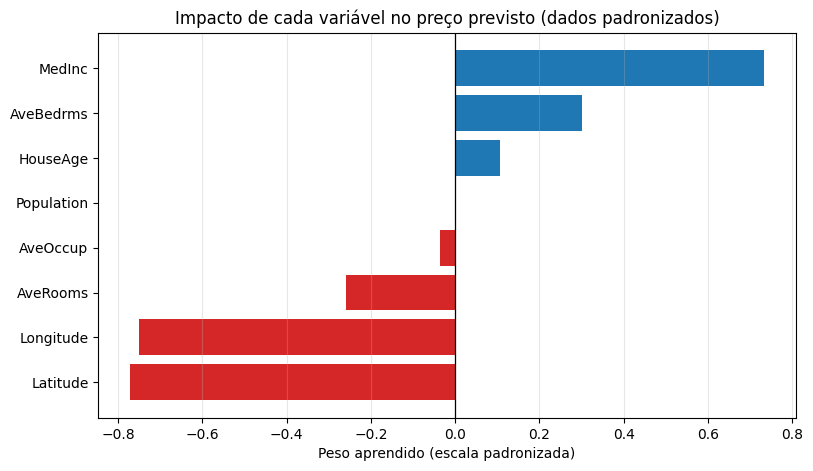

In [15]:
df_plot = df_pesos.sort_values('Peso (padronizado)', ascending=True)
cores = ['tab:red' if w < 0 else 'tab:blue' for w in df_plot['Peso (padronizado)']]

plt.figure(figsize=(9, 5))
plt.barh(df_plot['Variável'], df_plot['Peso (padronizado)'], color=cores)
plt.axvline(0, color='black', linewidth=0.9)
plt.xlabel('Peso aprendido (escala padronizada)')
plt.title('Impacto de cada variável no preço previsto (dados padronizados)')
plt.grid(True, axis='x', alpha=0.3)
plt.show()

### Interpretação dos pesos

1. **Quais variáveis mais aumentam o preço previsto?**
   - **`MedInc` (renda mediana)** tem disparado o maior peso positivo: quarteirões com maior poder aquisitivo têm imóveis substancialmente mais caros.
   - **`AveBedrms` (média de quartos)** aparece como o segundo maior peso positivo. Mantendo `AveRooms` (total de cômodos) fixo, um número maior de quartos significa maior proporção de dormitórios por domicílio, o que está associado a imóveis residenciais mais valorizados (ou regiões mais densas e caras).
   - **`HouseAge` (idade mediana das casas)** também tem peso positivo moderado: bairros mais antigos e consolidados na Califórnia tendem a ficar em áreas centrais/valorizadas.

2. **Quais variáveis mais diminuem o preço previsto?**
   - **`Latitude` e `Longitude`** têm os maiores pesos negativos. Na geografia da Califórnia, a costa se estende na diagonal noroeste–sudeste: aumentar a `Latitude` (ir para o norte) ou aumentar a `Longitude` (ir para o leste/interior, afastando-se do Oceano Pacífico) reduz fortemente o preço previsto, pois os imóveis mais caros concentram-se na faixa litorânea e no sul/Bay Area.
   - **`AveRooms` (média de cômodos)** apresenta peso negativo moderado quando `MedInc` e `AveBedrms` são mantidos constantes (devido à multicolinearidade com `AveBedrms` e ao fato de casas muito grandes em áreas rurais/afastadas custarem menos do que imóveis compactos nas grandes cidades).
   - **`AveOccup`** tem efeito negativo leve (mais pessoas dividindo o mesmo domicílio costuma indicar menor renda/valor do imóvel) e **`Population`** tem peso próximo de zero.

3. **Por que só faz sentido comparar os pesos entre si porque as entradas foram padronizadas?**
   - Sem padronização, cada variável estaria em uma unidade e escala completamente diferente (por exemplo, `Population` varia na casa dos milhares, enquanto `AveBedrms` varia perto de 1). Um peso numericamente pequeno multiplicando `Population` poderia produzir um impacto muito maior no preço do que um peso grande multiplicando `AveBedrms`.
   - Com o `StandardScaler`, todas as entradas passam a ter **média 0 e desvio padrão 1**. Assim, cada peso $w_j$ mede exatamente quantos desvios padrão o preço previsto $\hat{y}$ varia quando a variável $x_j$ aumenta em **1 desvio padrão** (mantendo as demais fixas). Só nessa escala comum a magnitude $|w_j|$ reflete diretamente a importância relativa de cada variável no modelo linear.

## 8. Conclusão

**O modelo é bom o suficiente?**  
A regressão linear múltipla representa um avanço claro sobre o baseline: reduz o RMSE no teste em cerca de **35%** (caindo da casa de US 115 mil para US 73 mil), mostrando que as 8 variáveis — especialmente renda e localização — carregam sinal relevante. Além disso, as curvas de treino e validação ficam muito próximas, indicando que não houve *overfitting*.  
Ainda assim, um erro médio quadrático em torno de **US 73 mil** para imóveis cujo preço médio é de US 207 mil (35% de erro relativo) é **alto demais para uso prático** em precificação imobiliária. O gráfico de valores reais vs. previstos também mostra limitações claras do modelo linear: ele chega a prever preços negativos para alguns casos extremos e não consegue capturar bem o teto em US 500 mil.

**O que tentar para melhorar?**
1. **Modelos não lineares**: a relação entre coordenadas geográficas (`Latitude`, `Longitude`) e o preço é fortemente não linear. Trocar `nn.Linear(8, 1)` por uma **rede neural MLP** (camadas ocultas + `ReLU` em PyTorch) ou usar modelos baseados em árvores (**Random Forest**, **Gradient Boosting / XGBoost / LightGBM**) costuma reduzir drasticamente o RMSE nesse dataset.
2. **Engenharia de atributos**: criar razões mais informativas (como `AveBedrms / AveRooms`, `Population / AveOccup`), distância até grandes centros urbanos ou até a costa, interações polinomiais e aplicar transformação logarítmica (`log1p`) em variáveis muito assimétricas (`AveRooms`, `AveBedrms`, `Population`, `AveOccup`).
3. **Tratamento de outliers e do teto no alvo**: filtrar ou limitar valores extremos nas variáveis de entrada e investigar o impacto dos registros truncados em US$ 500.000 (`MedHouseVal = 5.00001`).